# Neutrino-Induced Charm Production: Slow Rescaling Model vs Measurements

Comparison of the **Georgi–Politzer / Barnett Slow Rescaling Model** with historical inclusive experimental measurements from **CHORUS** (2011) and **E531** (1988) on nuclear emulsion targets.

Evaluating LHAPDF nuclear integration grid...


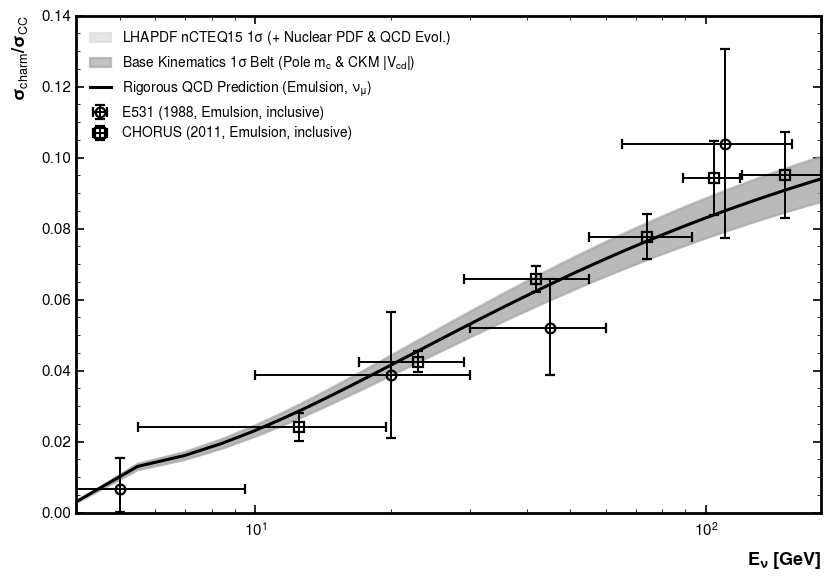

LHAPDF 6.5.3 loading all 33 PDFs in set nCTEQ15FullNuc_184_74
nCTEQ15FullNuc_184_74, version 1; 33 PDF members


In [ ]:
import os
import sys
import csv
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import lhapdf

# Ensure custom LHAPDF path is included
local_lhapdf_path = "/afs/cern.ch/work/i/idioniso/lhapdf_data"
if os.path.exists(local_lhapdf_path):
    lhapdf.pathsPrepend(local_lhapdf_path)

# Resolve CSV location relative to notebook directory or repo root
csv_path = Path("../scripts/diagnostics/measurements/neutrino_charm_cross_section_ratio_vs_enu.csv")
if not csv_path.exists():
    csv_path = Path("scripts/diagnostics/measurements/neutrino_charm_cross_section_ratio_vs_enu.csv")

# 1. Parse historical measurements (inclusive charm production on emulsion)
records = []
if csv_path.exists():
    with open(csv_path, "r", encoding="utf-8-sig") as f:
        clean_lines = [line for line in f if not line.strip().startswith("#")]
        reader = csv.DictReader(clean_lines)
        for row in reader:
            if row.get("channel", "").strip().lower() != "inclusive":
                continue
            records.append({
                "exp": row["experiment"].strip(),
                "x": float(row["E_nu_GeV"]),
                "dx_lo": float(row["dx_low"]),
                "dx_hi": float(row["dx_high"]),
                "y": float(row["ratio"]),
                "dy_lo": float(row["dy_low"]),
                "dy_hi": float(row["dy_high"]),  # <-- Fixed key name here
            })

# 2. Physics Constants & Emulsion Composition Setup
G_F = 1.1663787e-5     # GeV^-2
M_N = 0.938272         # Nucleon mass (GeV)
M_C = 1.43             # LO Pole charm mass (GeV)

V_CD = 0.221
V_CS = 0.975

# Nuclear Emulsion target composition (<Z/A> ~ 0.467)
F_P = 0.467
F_N = 1.0 - F_P

E_grid = np.linspace(4.0, 180.0, 120)

pdf_set_name = "nCTEQ15FullNuc_184_74" # Representative nuclear baseline for emulsion
try:
    pdf_set = lhapdf.getPDFSet(pdf_set_name)
    pdfs = pdf_set.mkPDFs()
except Exception as e:
    sys.exit(f"Failed to load LHAPDF set {pdf_set_name}: {e}")

# 3. Vectorized 2D Gauss-Legendre DIS Cross-Section Integrator
N_QUAD = 24  
nodes, weights = np.polynomial.legendre.leggauss(N_QUAD)

def integrate_xsec_lo(E_val, pdf_member, mc=M_C, vcd=V_CD, vcs=V_CS):
    xi_min = (mc**2) / (2.0 * M_N * E_val)
    if xi_min >= 1.0:
        sig_charm_lo = 0.0
    else:
        xi_nodes = 0.5 * (1.0 - xi_min) * nodes + 0.5 * (1.0 + xi_min)
        xi_weights = 0.5 * (1.0 - xi_min) * weights

        y_min = (mc**2) / (2.0 * M_N * E_val * xi_nodes)
        kin_factor = (1.0 - y_min)**2

        y_avg = 0.5 * (1.0 + y_min)
        mu2 = np.maximum(pdf_member.q2Min, 2.0 * M_N * E_val * xi_nodes * y_avg)

        d_p_xi = np.array([pdf_member.xfxQ2(1, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
        u_p_xi = np.array([pdf_member.xfxQ2(2, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
        
        d_N_xi = F_P * d_p_xi + F_N * u_p_xi
        s_N_xi = np.array([pdf_member.xfxQ2(3, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes

        s_prime = (vcs**2) * s_N_xi + (vcd**2) * d_N_xi
        integrand_charm = 2.0 * xi_nodes * s_prime * kin_factor
        sig_charm_lo = np.sum(xi_weights * integrand_charm)

    sig_charm_cm2 = 1.569e-38 * E_val * sig_charm_lo
    sig_qe_cm2 = (4.2e-40 * F_N) if E_val >= 4.5 else 0.0
    sig_charm_tot_cm2 = sig_charm_cm2 + sig_qe_cm2
    sig_cc_tot_cm2 = 0.677e-38 * E_val

    return sig_charm_tot_cm2, sig_cc_tot_cm2

def get_effective_b_mu(E):
    decay = np.exp(-(np.maximum(E, 4.5) - 4.5) / 18.0)
    f_D0 = 0.68 + (0.38 - 0.68) * decay
    f_Dp = 0.19 + (0.05 - 0.19) * decay
    f_Ds = 0.07 + (0.17 - 0.07) * decay
    f_Lc = 0.07 + (0.41 - 0.07) * decay
    tot = f_D0 + f_Dp + f_Ds + f_Lc
    return (f_D0/tot * 0.0687) + (f_Dp/tot * 0.172) + (f_Ds/tot * 0.080) + (f_Lc/tot * 0.045)

# 4. Compute Rigorous Curves
print("Evaluating LHAPDF nuclear integration grid...")
ratio_members = np.zeros((len(pdfs), len(E_grid)))
for m_idx, pdf in enumerate(pdfs):
    for e_idx, E_val in enumerate(E_grid):
        s_c, s_cc = integrate_xsec_lo(E_val, pdf)
        ratio_members[m_idx, e_idx] = (s_c / s_cc) if s_cc > 0 else 0.0

y_cen = ratio_members[0, :]
pdf_err = np.zeros(len(E_grid))
for e_idx in range(len(E_grid)):
    values = ratio_members[:, e_idx].tolist()
    unc = pdf_set.uncertainty(values)
    pdf_err[e_idx] = unc.errplus

# Build Cumulative Bands
rel_base = np.sqrt(0.065**2 + 0.018**2) # Charm mass + CKM
sigma_inner = y_cen * rel_base
sigma_outer = np.sqrt((y_cen * rel_base)**2 + pdf_err**2)

y_in_lo = np.maximum(0.0, y_cen - sigma_inner)
y_in_hi = y_cen + sigma_inner
y_out_hi = y_cen + sigma_outer

# 5. Plotting
fig, ax = plt.subplots(figsize=(8.5, 6.0))

ax.fill_between(
    E_grid, y_in_lo, y_out_hi,
    color="#dcdcdc", label=r"LHAPDF nCTEQ15 $1\sigma$ (+ Nuclear PDF & QCD Evol.)", zorder=1, alpha=0.7
)
ax.fill_between(
    E_grid, y_in_lo, y_in_hi,
    color="#a8a8a8", label=r"Base Kinematics $1\sigma$ Belt (Pole $m_c$ & CKM $|V_{cd}|$)", zorder=2, alpha=0.7
)
ax.plot(
    E_grid, y_cen,
    color="black", lw=2.2, label=r"QCD Prediction (Emulsion, $\nu_\mu$)", zorder=3
)

labels_map = {
    "E531": "E531 (1988, Emulsion, inclusive)",
    "CHORUS": "CHORUS (2011, Emulsion, inclusive)"
}
for exp, marker in [("E531", "o"), ("CHORUS", "s")]:
    pts = [r for r in records if r["exp"] == exp]
    if not pts:
        continue
    x = [p["x"] for p in pts]
    y = [p["y"] for p in pts]
    x_err = [[p["dx_lo"] for p in pts], [p["dx_hi"] for p in pts]]
    y_err = [[p["dy_lo"] for p in pts], [p["dy_hi"] for p in pts]]
    ax.errorbar(
        x, y, xerr=x_err, yerr=y_err,
        fmt=marker, mfc="none", mec="black", mew=1.6, markersize=7,
        ecolor="black", elinewidth=1.4, capsize=3.5, capthick=1.2,
        label=labels_map[exp], zorder=4
    )

ax.set_xlim(4.0, 180)
ax.set_ylim(0.0, 0.14)
ax.set_xscale("log")
ax.set_xlabel(r"$E_\nu$ [GeV]", fontsize=13, labelpad=8)
ax.set_ylabel(r"$\sigma_{\mathrm{charm}} / \sigma_{\mathrm{CC}}$", fontsize=13, labelpad=8)
ax.tick_params(axis="both", which="major", labelsize=11, direction="in")

leg = ax.legend(loc="upper left", fontsize=10.0, frameon=False, framealpha=0.92, facecolor="white")
leg.get_frame().set_linewidth(1.0)

plt.tight_layout()
plt.show()


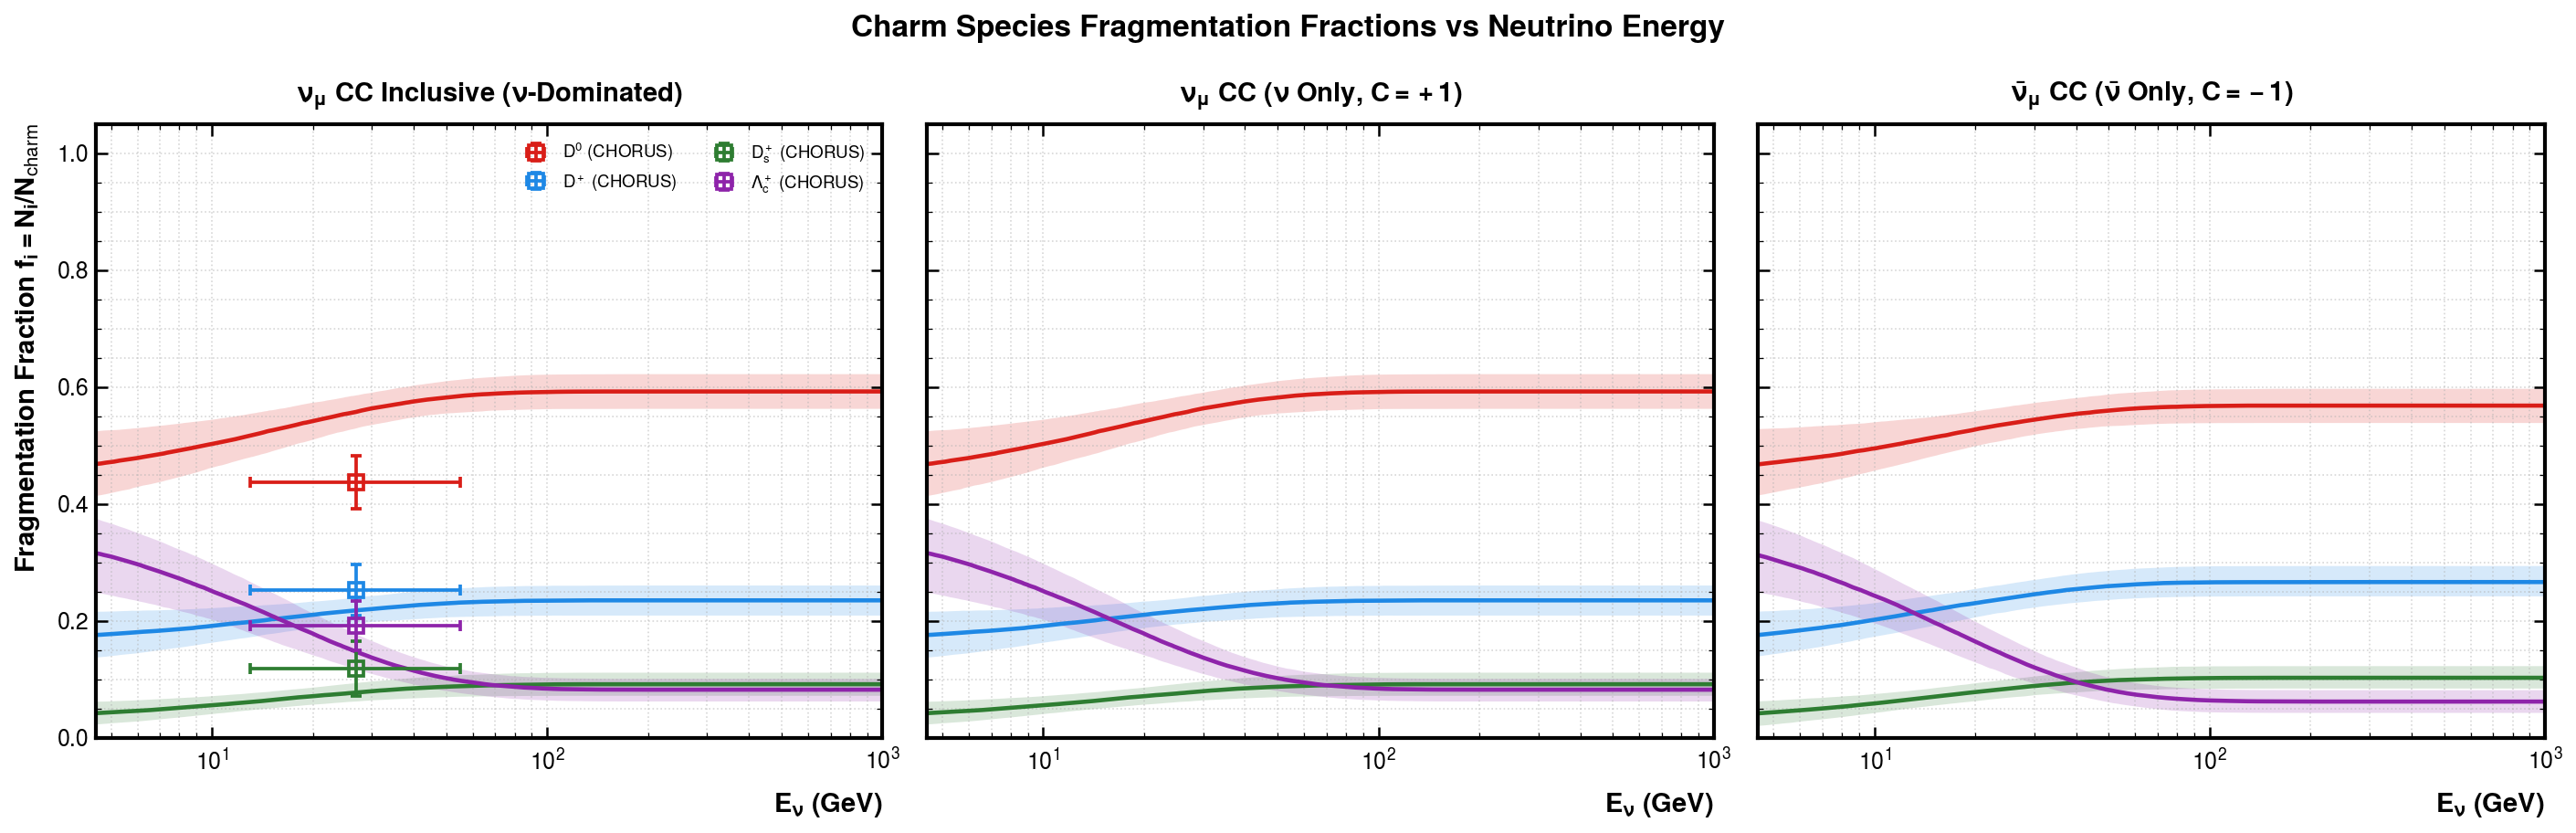

In [77]:
import os
import matplotlib.pyplot as plt
import numpy as np

# Optional import for mplhep (CERN/HEP styling standard)
try:
    import mplhep as hep
    plt.style.use(hep.style.ROOT)
    has_mplhep = True
except ImportError:
    has_mplhep = False

try:
    import uproot
    has_uproot = True
except ImportError:
    has_uproot = False


def calculate_species_fraction_model(
    e_min=4.5, e_max=1000.0, n_points=300, n_samples=2000, seed=42, mode="nu"
):
    """
    Computes Monte Carlo sampled parametric curves for charm hadronization fractions,
    accounting for threshold differences between neutrino (C = +1) and antineutrino (C = -1) modes.
    """
    np.random.seed(seed + (1 if mode == "antinu" else 0))
    e_pts = np.logspace(np.log10(max(4.5, e_min)), np.log10(e_max), n_points)
    species_keys = ["D0", "D+", "Lambda_c", "Ds+"]
    f_samples = {sp: np.zeros((n_samples, len(e_pts))) for sp in species_keys}

    for s in range(n_samples):
        tau_s = max(8.0, float(np.random.normal(18.0, 4.0)))

        # Slight asymmetry adjustments for antineutrino vs neutrino fragmentation parameters
        if mode == "antinu":
            w_inf = {
                "D0": max(0.38, float(np.random.normal(0.55, 0.04))),
                "D+": max(0.15, float(np.random.normal(0.26, 0.03))),
                "Lambda_c": max(0.02, float(np.random.normal(0.06, 0.02))),
                "Ds+": max(0.04, float(np.random.normal(0.10, 0.02))),
            }
        else:
            w_inf = {
                "D0": max(0.40, float(np.random.normal(0.58, 0.04))),
                "D+": max(0.12, float(np.random.normal(0.23, 0.03))),
                "Lambda_c": max(0.03, float(np.random.normal(0.08, 0.02))),
                "Ds+": max(0.04, float(np.random.normal(0.09, 0.02))),
            }

        sum_inf = sum(w_inf.values())
        f_inf_s = {k: v / sum_inf for k, v in w_inf.items()}

        w_thresh = {
            "D0": max(0.25, float(np.random.normal(0.45, 0.06))),
            "D+": max(0.08, float(np.random.normal(0.17, 0.04))),
            "Lambda_c": max(0.12, float(np.random.normal(0.30, 0.08))),
            "Ds+": max(0.01, float(np.random.normal(0.04, 0.02))),
        }
        sum_thresh = sum(w_thresh.values())
        f_thresh_s = {k: v / sum_thresh for k, v in w_thresh.items()}

        decay = np.exp(-(e_pts - 4.5) / tau_s)
        raw = {
            sp: f_inf_s[sp] + (f_thresh_s[sp] - f_inf_s[sp]) * decay
            for sp in species_keys
        }
        total_raw = sum(raw.values())

        for sp in species_keys:
            f_samples[sp][s, :] = raw[sp] / total_raw

    f_med = {sp: np.median(f_samples[sp], axis=0) for sp in species_keys}
    f_low = {sp: np.percentile(f_samples[sp], 16, axis=0) for sp in species_keys}
    f_high = {sp: np.percentile(f_samples[sp], 84, axis=0) for sp in species_keys}
    return e_pts, f_med, f_low, f_high


def load_mc_points(root_file_path):
    if not root_file_path or not os.path.exists(root_file_path) or not has_uproot:
        return {}
    mc_data = {}
    try:
        with uproot.open(root_file_path) as f:
            if "Summary" in f:
                summary = f["Summary"]
                for k in summary.keys():
                    k_clean = k.split(";")[0]
                    if k_clean.startswith("g_fraction_"):
                        g = summary[k]
                        vals = g.values()
                        errs_lo = g.errors("low")
                        errs_hi = g.errors("high")
                        mc_data[k_clean] = {
                            "x": np.array(vals[0]),
                            "y": np.array(vals[1]),
                            "ex_lo": np.array(errs_lo[0]),
                            "ex_hi": np.array(errs_hi[0]),
                            "ey_lo": np.array(errs_lo[1]),
                            "ey_hi": np.array(errs_hi[1]),
                        }
    except Exception:
        pass
    return mc_data


# 1. Load ROOT MC points
root_file = "/eos/user/i/idioniso/snd-numu-charm/charm_diagnostic_nu14_2022.root"
mc_data = load_mc_points(root_file)

# 2. Metadata styling dictionaries
meta = {
    "D0": {"color": "#d91e18", "label": r"$D^0$", "marker": "o", "mc_key": "D0"},
    "D+": {"color": "#1e88e5", "label": r"$D^+$", "marker": "^", "mc_key": "Dplus"},
    "Ds+": {"color": "#2e7d32", "label": r"$D_s^+$", "marker": "s", "mc_key": "Ds"},
    "Lambda_c": {"color": "#8e24aa", "label": r"$\Lambda_c^+$", "marker": "D", "mc_key": "Lambda_c"},
}

anti_meta = {
    "D0": {"color": "#d91e18", "label": r"$\bar{D}^0$", "marker": "o", "mc_key": "anti_D0"},
    "D+": {"color": "#1e88e5", "label": r"$D^-$", "marker": "^", "mc_key": "Dminus"},
    "Ds+": {"color": "#2e7d32", "label": r"$D_s^-$", "marker": "s", "mc_key": "Ds_minus"},
    "Lambda_c": {"color": "#8e24aa", "label": r"$\bar{\Lambda}_c^-$", "marker": "D", "mc_key": "anti_Lambda_c"},
}

chorus_vals = {
    "D0": (0.437, 0.045),
    "D+": (0.253, 0.044),
    "Ds+": (0.118, 0.047),
    "Lambda_c": (0.192, 0.042),
}

species_order = ["D0", "D+", "Ds+", "Lambda_c"]

# Panel configurations with explicit model modes ("nu" vs "antinu")
panels = [
    ("inclusive", r"$\nu_\mu$ CC Inclusive ($\nu$-Dominated)", True, False, "", "nu"),
    ("nu_only", r"$\nu_\mu$ CC ($\nu$ Only, $C=+1$)", False, False, "_nu_only", "nu"),
    ("antinu_only", r"$\bar{\nu}_\mu$ CC ($\bar{\nu}$ Only, $C=-1$)", False, True, "_antinu_only", "antinu"),
]

# 3. Plotting Setup
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 13,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 3,
    'ytick.minor.size': 3,
    'xtick.major.width': 1.2,
    'ytick.major.width': 1.2,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
})

fig, axes = plt.subplots(1, 3, figsize=(19, 6.2), sharey=True, dpi=150)

for ax, (_, subtitle, show_chorus, is_anti, suffix, model_mode) in zip(axes, panels):
    cur_meta = anti_meta if is_anti else meta

    # Generate independent model curves for this specific panel mode
    e_pts, f_med, f_low, f_high = calculate_species_fraction_model(
        e_min=4.5, e_max=1000.0, n_points=300, n_samples=2000, seed=42, mode=model_mode
    )

    # Plot continuous uncertainty bands and central lines
    for sp in species_order:
        info = cur_meta[sp]
        col = info["color"]
        ax.fill_between(
            e_pts, f_low[sp], f_high[sp],
            color=col, alpha=0.18, edgecolor="none", zorder=1
        )
        ax.plot(
            e_pts, f_med[sp],
            color=col, linewidth=2.2, linestyle="-", zorder=2
        )

    # Overlay CHORUS data points on the inclusive panel
    if show_chorus:
        for sp in species_order:
            info = cur_meta[sp]
            c_val, c_err = chorus_vals[sp]
            ax.errorbar(
                27.0, c_val,
                xerr=[[14.0], [28.0]],
                yerr=[[c_err], [c_err]],
                fmt="s", mfc="none", mec=info["color"], ecolor=info["color"],
                markersize=8, capsize=3, elinewidth=1.8, markeredgewidth=1.8,
                label=f"{info['label']} (CHORUS)", zorder=4
            )

    # Overlay ROOT MC validation points corresponding to each panel's specific suffix
    for sp in species_order:
        info = cur_meta[sp]
        mc_k = f"g_fraction_{info['mc_key']}_vs_nu_energy{suffix}"
        if mc_k in mc_data:
            d = mc_data[mc_k]
            if len(d["x"]) > 0:
                ax.errorbar(
                    d["x"], d["y"],
                    xerr=[d["ex_lo"], d["ex_hi"]],
                    yerr=[d["ey_lo"], d["ey_hi"]],
                    fmt=info["marker"], color=info["color"],
                    markersize=6, capsize=2, linewidth=1.5,
                    label=f"{info['label']} (MC)", zorder=5
                )

    ax.set_xscale("log")
    ax.set_xlim(4.5, 1000)
    ax.set_ylim(0.0, 1.05)
    ax.set_xlabel(r"$E_\nu\ \mathbf{(GeV)}$", fontsize=14, labelpad=8)
    ax.set_title(subtitle, fontsize=14, pad=12, fontweight='bold')
    ax.tick_params(axis="both", which="major", labelsize=12)
    ax.grid(True, which="both", linestyle=":", alpha=0.5)
    
    # Render legend if handles exist on this axis
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(
            loc="upper right",
            fontsize=9.0,
            ncol=2 if show_chorus else 1,
            framealpha=0.9,
            edgecolor="black"
        )

axes[0].set_ylabel(r"Fragmentation Fraction $f_i = N_i / N_{\rm charm}$", fontsize=14, labelpad=8)
plt.suptitle(
    "Charm Species Fragmentation Fractions vs Neutrino Energy",
    fontsize=16,
    y=0.98,
    fontweight='bold'
)
plt.tight_layout()
plt.show()

In [49]:
import os
import sys
import ctypes

# The exact successful paths you resolved in your terminal
lcg_lhapdf = "/cvmfs/sft.cern.ch/lcg/releases/MCGenerators/lhapdf/6.5.3-3fa11/x86_64-el9-gcc11-opt"
exact_py_path = f"{lcg_lhapdf}/lib/python3.9/site-packages"

# 1. Point Python to the LHAPDF site-packages directory
if exact_py_path not in sys.path:
    sys.path.insert(0, exact_py_path)

# 2. Pre-load the underlying C++ shared library directly.
# This mimics LD_LIBRARY_PATH but works inside an already-running Jupyter kernel.
lib_path = f"{lcg_lhapdf}/lib/libLHAPDF.so"
if not os.path.exists(lib_path):
    lib_path = f"{lcg_lhapdf}/lib64/libLHAPDF.so" # Fallback just in case
ctypes.CDLL(lib_path, mode=ctypes.RTLD_GLOBAL)

# 3. Set the data paths for the PDF sets and config files
home_dir = os.environ.get('HOME', '/home/idioniso')
os.environ["LHAPDF_DATA_PATH"] = f"{home_dir}/.Misc/lhapdf_data:{lcg_lhapdf}/share/LHAPDF"

# 4. Import and test
import lhapdf

print("Search paths:", lhapdf.paths())
pdf = lhapdf.mkPDF("nCTEQ15FullNuc_184_74", 0)
print(f"Successfully loaded: {pdf.set().name} (Total members: {pdf.set().size})")

Search paths: ['/home/idioniso/.Misc/lhapdf_data', '/cvmfs/sft.cern.ch/lcg/releases/MCGenerators/lhapdf/6.5.3-3fa11/x86_64-el9-gcc11-opt/share/LHAPDF', '/build/jenkins/workspace/lcg_release_pipeline/install/MCGenerators/lhapdf/6.5.3/x86_64-el9-gcc11-opt/share/LHAPDF']
Successfully loaded: nCTEQ15FullNuc_184_74 (Total members: 33)
LHAPDF 6.5.3 loading /home/idioniso/.Misc/lhapdf_data/nCTEQ15FullNuc_184_74/nCTEQ15FullNuc_184_74_0000.dat
nCTEQ15FullNuc_184_74 PDF set, member #0, version 1; LHAPDF ID = 102900


Loaded nCTEQ15FullNuc_184_74 with 33 members.
Computing cross-section ratios across all nPDF Hessian members...


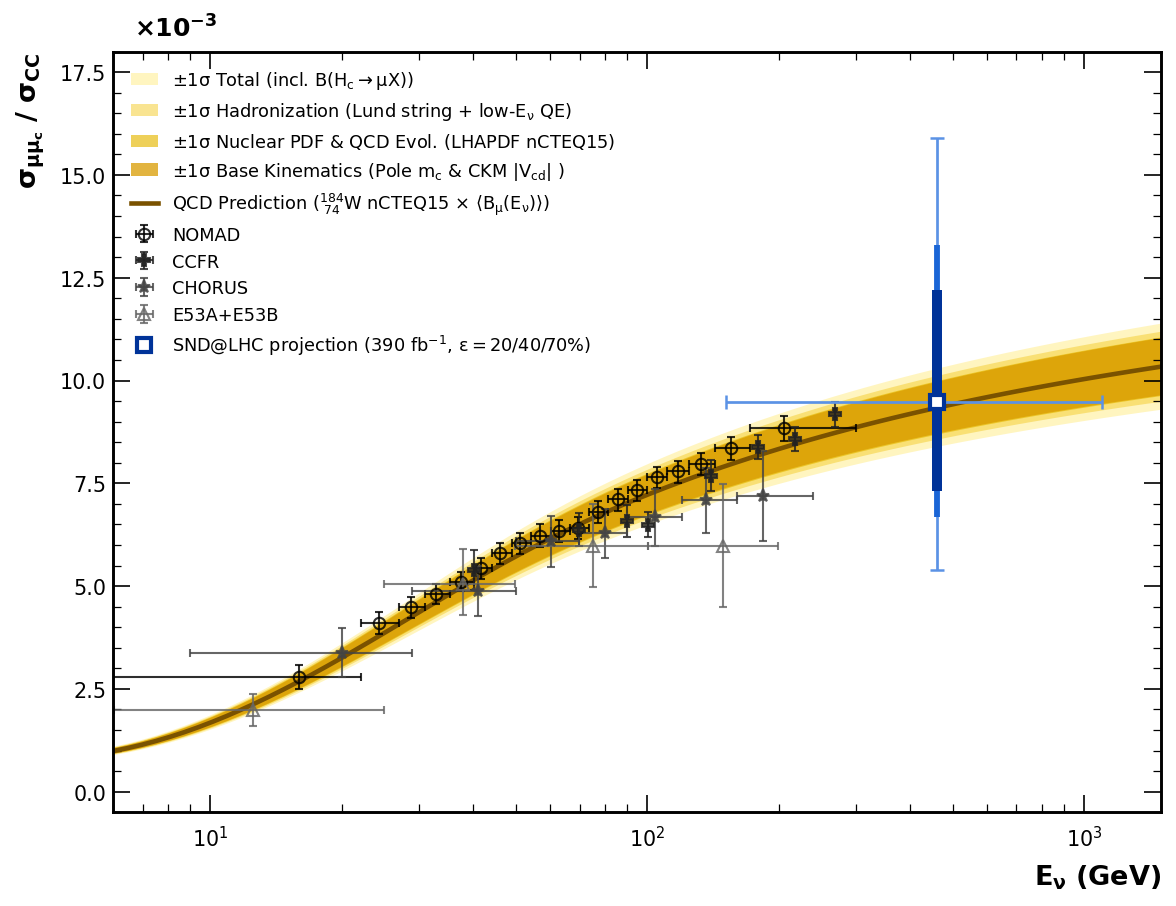

LHAPDF 6.5.3 loading all 33 PDFs in set nCTEQ15FullNuc_184_74
nCTEQ15FullNuc_184_74, version 1; 33 PDF members


In [62]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import lhapdf

# Ensure custom LHAPDF path is included
local_lhapdf_path = "/afs/cern.ch/work/i/idioniso/lhapdf_data"
if os.path.exists(local_lhapdf_path):
    lhapdf.pathsPrepend(local_lhapdf_path)

# -------------------------------------------------------------------------
# 1. Physics Constants & Kinematics Setup
# -------------------------------------------------------------------------
G_F = 1.1663787e-5     # GeV^-2
M_N = 0.938272         # Nucleon mass (GeV)
M_C = 1.43             # LO Pole charm mass (GeV) - absorbs NLO high-E effects

# CKM Matrix Elements
V_CD = 0.221
V_CS = 0.975

# Tungsten Target Isospin Fractions (Z=74, A=184)
F_P = 74.0 / 183.84
F_N = 1.0 - F_P

E_grid = np.logspace(np.log10(6.0), np.log10(1500.0), 75)

pdf_set_name = "nCTEQ15FullNuc_184_74"
try:
    pdf_set = lhapdf.getPDFSet(pdf_set_name)
    pdfs = pdf_set.mkPDFs()
    print(f"Loaded {pdf_set_name} with {len(pdfs)} members.")
except Exception as e:
    sys.exit(f"Failed to load LHAPDF set {pdf_set_name}: {e}\nCheck LHAPDF_DATA_PATH.")

# -------------------------------------------------------------------------
# 2. Vectorized 2D Gauss-Legendre DIS Cross-Section Integrator
# -------------------------------------------------------------------------
N_QUAD = 24  
nodes, weights = np.polynomial.legendre.leggauss(N_QUAD)

def integrate_xsec_lo(E_val, pdf_member, mc=M_C, vcd=V_CD, vcs=V_CS):
    """
    Computes rigorous sigma_charm and sigma_CC integrating over the bound 
    nuclear PDFs, normalized to the empirical total CC cross-section.
    """
    # ------------------ A. Charm Production (Numerator) ------------------
    xi_min = (mc**2) / (2.0 * M_N * E_val)
    if xi_min >= 1.0:
        sig_charm_lo = 0.0
    else:
        xi_nodes = 0.5 * (1.0 - xi_min) * nodes + 0.5 * (1.0 + xi_min)
        xi_weights = 0.5 * (1.0 - xi_min) * weights

        y_min = (mc**2) / (2.0 * M_N * E_val * xi_nodes)
        kin_factor = (1.0 - y_min)**2

        y_avg = 0.5 * (1.0 + y_min)
        mu2 = np.maximum(pdf_member.q2Min, 2.0 * M_N * E_val * xi_nodes * y_avg)

        # Query BOUND PROTON PDFs
        d_p_xi = np.array([pdf_member.xfxQ2(1, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
        u_p_xi = np.array([pdf_member.xfxQ2(2, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
        
        # Construct AVERAGE NUCLEON down-quark density
        d_N_xi = F_P * d_p_xi + F_N * u_p_xi
        
        # Strange sea is isoscalar (s_p = s_n)
        s_N_xi = np.array([pdf_member.xfxQ2(3, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes

        s_prime = (vcs**2) * s_N_xi + (vcd**2) * d_N_xi
        integrand_charm = 2.0 * xi_nodes * s_prime * kin_factor
        sig_charm_lo = np.sum(xi_weights * integrand_charm)

    # Convert unitless integral to absolute cross-section in cm^2
    # Prefactor: G_F^2 * M_N / pi * (hbar c)^2
    sig_charm_cm2 = 1.569e-38 * E_val * sig_charm_lo
    
    # Quasi-Elastic Charm Cross-Section (~4.2e-40 cm^2 total scaled by target neutron fraction)
    sig_qe_cm2 = (4.2e-40 * F_N) if E_val >= 4.5 else 0.0
    
    # Total Absolute Charm Cross-Section
    sig_charm_tot_cm2 = sig_charm_cm2 + sig_qe_cm2

    # ------------------ B. Inclusive CC DIS (Denominator) -----------------
    # Use the exact empirical linear cross-section for the total inclusive denominator
    sig_cc_tot_cm2 = 0.677e-38 * E_val

    return sig_charm_tot_cm2, sig_cc_tot_cm2

# -------------------------------------------------------------------------
# 3. Energy-Dependent Branching Ratio <B_mu(E_nu)>
# -------------------------------------------------------------------------
def get_effective_b_mu(E):
    decay = np.exp(-(np.maximum(E, 4.5) - 4.5) / 18.0)
    
    f_D0 = 0.68 + (0.38 - 0.68) * decay
    f_Dp = 0.19 + (0.05 - 0.19) * decay
    f_Ds = 0.07 + (0.17 - 0.07) * decay
    f_Lc = 0.07 + (0.41 - 0.07) * decay
    
    tot = f_D0 + f_Dp + f_Ds + f_Lc
    f_D0, f_Dp, f_Ds, f_Lc = f_D0/tot, f_Dp/tot, f_Ds/tot, f_Lc/tot

    # Updated with exact PDG averages reported in neutrino data
    return (f_D0 * 0.0687) + (f_Dp * 0.172) + (f_Ds * 0.080) + (f_Lc * 0.045)

B_mu_grid = get_effective_b_mu(E_grid)

# -------------------------------------------------------------------------
# 4. Compute Nominal Prediction & LHAPDF Hessian Uncertainty Envelope
# -------------------------------------------------------------------------
print("Computing cross-section ratios across all nPDF Hessian members...")

ratio_members = np.zeros((len(pdfs), len(E_grid)))

for m_idx, pdf in enumerate(pdfs):
    for e_idx, E_val in enumerate(E_grid):
        s_c, s_cc = integrate_xsec_lo(E_val, pdf)
        ratio_members[m_idx, e_idx] = (s_c / s_cc) if s_cc > 0 else 0.0

y_nominal = ratio_members[0, :] * B_mu_grid * 1e3

pdf_err_lo = np.zeros(len(E_grid))
pdf_err_hi = np.zeros(len(E_grid))

for e_idx in range(len(E_grid)):
    values = ratio_members[:, e_idx].tolist()
    unc = pdf_set.uncertainty(values)
    pdf_err_lo[e_idx] = unc.errminus * B_mu_grid[e_idx] * 1e3
    pdf_err_hi[e_idx] = unc.errplus   * B_mu_grid[e_idx] * 1e3

# -------------------------------------------------------------------------
# 5. Build Cumulative Uncertainty Bands
# -------------------------------------------------------------------------
# Tier 1: Charm Pole Mass & CKM Base
rel_mc = 0.065  
rel_ckm = 0.018
sigma_1_lo = y_nominal * np.sqrt(rel_mc**2 + rel_ckm**2)
sigma_1_hi = y_nominal * np.sqrt(rel_mc**2 + rel_ckm**2)

# Tier 2: Tier 1 + Rigorous nCTEQ15 Nuclear PDF
sigma_2_lo = np.sqrt(sigma_1_lo**2 + pdf_err_lo**2)
sigma_2_hi = np.sqrt(sigma_1_hi**2 + pdf_err_hi**2)

# Tier 3: Tier 2 + Hadronization Variance
var_frag = (0.045 * y_nominal)**2
sigma_3_lo = np.sqrt(sigma_2_lo**2 + var_frag)
sigma_3_hi = np.sqrt(sigma_2_hi**2 + var_frag)

# Tier 4: Tier 3 + PDG Semi-Muonic Branching Ratios
var_br = (0.059 * y_nominal)**2
sigma_4_lo = np.sqrt(sigma_3_lo**2 + var_br)
sigma_4_hi = np.sqrt(sigma_3_hi**2 + var_br)

# -------------------------------------------------------------------------
# 6. Plotting
# -------------------------------------------------------------------------
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 12,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
})

fig, ax = plt.subplots(figsize=(8, 6.2), dpi=150)

c_line = '#7a5200'
c1 = '#d99b00'
c2 = '#e5b800'
c3 = '#f5cf38'
c4 = '#ffea75'

ax.fill_between(E_grid, y_nominal - sigma_4_lo, y_nominal + sigma_4_hi, color=c4, alpha=0.45, edgecolor='none', 
                label=r'$\pm 1\sigma$ Total (incl. $\mathcal{B}(H_c \to \mu X)$)')

ax.fill_between(E_grid, y_nominal - sigma_3_lo, y_nominal + sigma_3_hi, color=c3, alpha=0.55, edgecolor='none', 
                label=r'$\pm 1\sigma$ Hadronization (Lund string + low-$E_\nu$ QE)')

ax.fill_between(E_grid, y_nominal - sigma_2_lo, y_nominal + sigma_2_hi, color=c2, alpha=0.65, edgecolor='none', 
                label=r'$\pm 1\sigma$ Nuclear PDF & QCD Evol. (LHAPDF nCTEQ15)')

ax.fill_between(E_grid, y_nominal - sigma_1_lo, y_nominal + sigma_1_hi, color=c1, alpha=0.75, edgecolor='none', 
                label=r'$\pm 1\sigma$ Base Kinematics (Pole $m_c$ & CKM $|V_{cd}|$ )')

ax.plot(E_grid, y_nominal, color=c_line, lw=2.2, linestyle='-', 
        label=r'QCD Prediction ($^{184}_{\ 74}\mathrm{W}$ nCTEQ15 $\times\ \langle B_\mu(E_\nu)\rangle$)')

styles = {
    'NOMAD': {'fmt': 'o', 'color': '#000000', 'mfc': 'none', 'ms': 5.5, 'label': 'NOMAD'},
    'CCFR': {'fmt': 'P', 'color': '#222222', 'mfc': '#222222', 'ms': 6.0, 'label': 'CCFR'},
    'CHORUS': {'fmt': '*', 'color': '#444444', 'mfc': '#444444', 'ms': 6.5, 'label': 'CHORUS'},
    'E53A+E53B': {'fmt': '^', 'color': '#666666', 'mfc': 'none', 'ms': 5.5, 'label': 'E53A+E53B'},
}

csv_path = '/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/measurements/neutrino_charm_dimuon_ratio_vs_enu.csv'
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path, comment="#")
    for exp, sty in styles.items():
        sub = df[df['experiment'] == exp]
        ax.errorbar(sub['E_nu_GeV'], sub['ratio_times_10^-3'], xerr=[sub['dx_low'], sub['dx_high']], 
                    yerr=[sub['dy_low'], sub['dy_high']], fmt=sty['fmt'], color=sty['color'], 
                    mfc=sty['mfc'], markersize=sty['ms'], elinewidth=1.0, capsize=2, alpha=0.82, label=sty['label'])

E_snd = 461.4
y_snd = 9.48
dx_lo_snd, dx_hi_snd = 310.0, 640.0
dy_lo_real, dy_hi_real = 4.09, 6.41
dy_lo_opt, dy_hi_opt   = 2.81, 3.81
dy_lo_perf, dy_hi_perf = 2.16, 2.71

c_real, c_opt, c_perf = '#5b92e5', '#1a65d6', '#003399'

ax.errorbar(E_snd, y_snd, xerr=[[dx_lo_snd], [dx_hi_snd]], yerr=[[dy_lo_real], [dy_hi_real]], 
            fmt='none', ecolor=c_real, elinewidth=1.3, capsize=3.5, capthick=1.2, zorder=6)
ax.errorbar(E_snd, y_snd, yerr=[[dy_lo_opt], [dy_hi_opt]], 
            fmt='none', ecolor=c_opt, elinewidth=2.8, capsize=0, zorder=7)
ax.errorbar(E_snd, y_snd, yerr=[[dy_lo_perf], [dy_hi_perf]], fmt='s', color=c_perf, mfc='white', 
            mec=c_perf, mew=2.0, markersize=6.8, elinewidth=4.8, capsize=0, zorder=8, 
            label=r'SND@LHC projection ($390\ \mathrm{fb}^{-1}$, $\varepsilon=20/40/70\%$)')

ax.set_xscale('log')
ax.set_xlim(6.0, 1500.0)
ax.set_ylim(-0.5, 18.0)
ax.set_xlabel(r'$E_{\nu}\ \mathbf{(GeV)}$', fontsize=13, loc='right', labelpad=6)
ax.set_ylabel(r'$\sigma_{\mu\mu_c}\ /\ \sigma_{\mathbf{CC}}$', fontsize=13, loc='top', labelpad=6)
ax.text(0.02, 1.02, r'$\times 10^{-3}$', transform=ax.transAxes, fontsize=12, fontweight='bold')

ax.legend(frameon=False, edgecolor='black', facecolor='white', framealpha=0.92, fontsize=8.5, loc='upper left')

plt.tight_layout()
plt.show()